<a href="https://colab.research.google.com/github/ivansuarez-AU/MAI510_M5_Assignment_5_2/blob/main/MAI510_M5_Assignment_5_2_RetailVision_Model_Showdown_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛍️ RetailVision AI — The Model Showdown! 🧠⚖️
## MAI 510 · Module 5 · Assignment 5.2 — A Neural Regressor on the Same Question
**Two competitors:** the established BG/NBD + Gamma-Gamma probabilistic approach versus a Keras neural regressor. **One target:** actual future gross positive-sale revenue over the same 75-day held-out period.

**Mission:** Can the neural model earn its place? Generate reproducible results, predicted-vs-actual charts, a top-50 overlap dashboard, an optional Qwen critique, a named Word report, and a final ZIP.

**Classroom flow:** 00–11 data and model build → 12–17 evidence, ranking and dashboard → 18–20 optional Ollama → 21–23 reporting and ZIP.

**Fairness note:** The 12-month discounted CLV forecast from Assignment 5.1 is NOT compared directly against observed 75-day sales. Here we refit the established model on the earlier transaction period and forecast the very same 75-day held-out gross sales that the neural model predicts. The baseline models have different assumptions; neither is guaranteed to win.

**Practice vs submission:** Synthetic data + `DEMO_MODE=True` is for practice. Use approved real data and `DEMO_MODE=False` for your final work.

### LAB 00 — Student check-in and mission controls 🎫
**Required:** enter your first and last name. Outputs and the report will carry your name. In the settings: `SOURCE = 'DEMO_SYNTHETIC'` for the fast classroom activity; `'UCI_REAL'`, `'UPLOAD'`, or `'A51_ZIP'` for real data. An Assignment 5.1 ZIP is optional: the notebook will reuse its cleaned customer-day transactions **but deliberately refit the baseline at this assignment's held-out cutoff**. Change `HOLDOUT_DAYS` only before running the whole notebook.

In [1]:
from pathlib import Path
import os, re, json, time, io, math, shutil, zipfile, hashlib, warnings
from datetime import datetime, timezone
STUDENT_NAME = input('Enter your FIRST and LAST name (required): ').strip()
if len(STUDENT_NAME.split()) < 2 or len(re.sub('[^A-Za-z]','',STUDENT_NAME)) < 4:
    raise ValueError('First and last name required. Rerun LAB 00.')
SAFE_NAME=re.sub('[^A-Za-z0-9]+','_',STUDENT_NAME).strip('_')
DEMO_MODE=True                # False required for final assessed run
SOURCE='DEMO_SYNTHETIC'      # 'DEMO_SYNTHETIC' | 'UCI_REAL' | 'UPLOAD' | 'A51_ZIP'
HOLDOUT_DAYS=75              # Future test horizon; common to BOTH models
SEED=510
NN_EPOCHS=12 if DEMO_MODE else 65
NN_BATCH=64 if DEMO_MODE else 128
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
BASE=Path('/content')/f'MAI510_M5_A52_{SAFE_NAME}_{RUN_ID}'
DIRS={k:BASE/k for k in ['source_data','clean_data','tables','figures','dashboards','models','reports','proof','ai_review','submission_uploads']}
for d in DIRS.values():d.mkdir(parents=True,exist_ok=True)
RUN_INFO=dict(student_name=STUDENT_NAME,course='MAI 510',assignment='5.2',source=SOURCE,demo_mode=DEMO_MODE,holdout_days=HOLDOUT_DAYS,seed=SEED,created_utc=RUN_ID)
(DIRS['proof']/'student_run_settings.json').write_text(json.dumps(RUN_INFO,indent=2))
print('Welcome',STUDENT_NAME,'|',('DEMO PRACTICE' if DEMO_MODE else 'FULL RUN'))
print('Outputs:', BASE)

Enter your FIRST and LAST name (required): Ivan Suarez
Welcome Ivan Suarez | DEMO PRACTICE
Outputs: /content/MAI510_M5_A52_Ivan_Suarez_20261124_224524


### LAB 01 — Install the tools 🧰
**Why:** Pandas manipulates transactions; `lifetimes` fits the established BG/NBD and Gamma-Gamma models; TensorFlow/Keras trains the neural regressor; scikit-learn scales input features and scores the models; Plotly creates shareable HTML dashboards; python-docx generates the Word report. In Colab, install once per runtime.

In [2]:
%pip -q install 'lifetimes==0.11.3' 'plotly>=5.15' 'python-docx>=1.1' 'openpyxl>=3.1'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, plotly.express as px, plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown
from scipy.stats import pearsonr
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from docx import Document
np.random.seed(SEED); tf.random.set_seed(SEED)
print('Versions: TensorFlow',tf.__version__,'Pandas',pd.__version__)

Versions: TensorFlow 2.21.0 Pandas 2.2.3


### LAB 02 — Bring your dataset or Assignment 5.1 ZIP 📦
Options: `UCI_REAL` downloads the official UCI Online Retail archive; `UPLOAD` accepts your CSV/XLSX; `A51_ZIP` accepts the final Submission ZIP from 5.1 and extracts `customer_daily_purchases.csv`, preserving the original cleaning decisions; `DEMO_SYNTHETIC` uses the practice CSV included in this teaching package (upload it when prompted or the notebook generates it). **Do not use future data for feature engineering.** If you import the 5.1 ZIP, we will **refit** both models and create a fresh future holdout so both are evaluated on equal terms.

In [3]:
from google.colab import files
import urllib.request

def synthetic_daily():
    rng=np.random.default_rng(SEED)
    rows=[]
    for j in range(1,551):
        cid=f'DEMO-{j:05d}'; start=int(rng.integers(0,120))
        count=max(1,int(rng.poisson(6.2)))
        days=sorted(set([start]+[int(v) for v in rng.integers(start,350,size=count-1)]))
        spend=float(rng.gamma(2.5,22)+4)
        for k,day in enumerate(days):
            rows.append({'CustomerID':cid,'PurchaseDate':pd.Timestamp('2024-01-01')+pd.Timedelta(days=day),
                         'Sales':round(spend*float(rng.lognormal(0,.32)),2)})
    return pd.DataFrame(rows)

if SOURCE=='DEMO_SYNTHETIC':
    print('Synthetic practice: creating compatible customer-day records (non-submission data).')
    purchases=synthetic_daily()
    purchases.to_csv(DIRS['source_data']/'DEMO_SYNTHETIC_customer_daily_purchases.csv',index=False)
elif SOURCE=='A51_ZIP':
    up=files.upload()
    assert len(up)==1,'Upload exactly ONE Assignment 5.1 ZIP.'
    name,content=next(iter(up.items()))
    (DIRS['source_data']/Path(name).name).write_bytes(content)
    with zipfile.ZipFile(io.BytesIO(content)) as z:
        paths=[n for n in z.namelist() if n.endswith('customer_daily_purchases.csv')]
        if not paths:raise ValueError('5.1 ZIP missing clean_data/customer_daily_purchases.csv. Upload real transaction CSV instead.')
        purchases=pd.read_csv(z.open(paths[0]))
        cleaning=[n for n in z.namelist() if n.endswith('REQUIRED_cleaning_decision_log.csv')]
        if cleaning:
            (DIRS['proof']/'A51_imported_cleaning_decision_log.csv').write_bytes(z.read(cleaning[0]))
    print('Imported cleaned purchase-day records from 5.1:',len(purchases))
else:
    if SOURCE=='UCI_REAL':
        src='https://archive.ics.uci.edu/static/public/352/online+retail.zip'
        path=DIRS['source_data']/'UCI_Online_Retail_original.zip'
        urllib.request.urlretrieve(src,str(path))
        with zipfile.ZipFile(path) as z:
            entry=next((n for n in z.namelist() if n.lower().endswith(('.xlsx','.csv'))),None)
            if not entry:raise ValueError('No usable data file found in official UCI download.')
            blob=z.read(entry)
            raw=pd.read_excel(io.BytesIO(blob)) if entry.lower().endswith('.xlsx') else pd.read_csv(io.BytesIO(blob))
    elif SOURCE=='UPLOAD':
        up=files.upload(); assert len(up)==1,'Upload one original CSV or XLSX.'
        name,blob=next(iter(up.items()))
        (DIRS['source_data']/Path(name).name).write_bytes(blob)
        raw=pd.read_excel(io.BytesIO(blob)) if name.lower().endswith('.xlsx') else pd.read_csv(io.BytesIO(blob),low_memory=False)
    else:raise ValueError('Invalid SOURCE value: '+SOURCE)
    mandatory={'InvoiceNo','InvoiceDate','CustomerID','Quantity','UnitPrice'}
    if mandatory-set(raw.columns):raise ValueError('Missing columns: '+str(mandatory-set(raw.columns)))
    before=len(raw); raw=raw.copy()
    raw['InvoiceDate']=pd.to_datetime(raw['InvoiceDate'],errors='coerce')
    raw['Quantity']=pd.to_numeric(raw['Quantity'],errors='coerce')
    raw['UnitPrice']=pd.to_numeric(raw['UnitPrice'],errors='coerce')
    clean=raw.loc[raw['CustomerID'].notna() & raw['InvoiceDate'].notna() &
        (raw['Quantity']>0)&(raw['UnitPrice']>0) &
        ~raw['InvoiceNo'].astype(str).str.upper().str.startswith('C')].drop_duplicates().copy()
    clean['CustomerID']=clean['CustomerID'].astype(str).str.replace(r'\.0$','',regex=True).str.strip()
    clean['Sales']=clean['Quantity']*clean['UnitPrice']
    clean=clean[np.isfinite(clean['Sales'])&(clean['Sales']>0)]
    invoices=clean.groupby(['CustomerID','InvoiceNo'],as_index=False).agg(InvoiceDate=('InvoiceDate','min'),Sales=('Sales','sum'))
    invoices['PurchaseDate']=invoices['InvoiceDate'].dt.normalize()
    purchases=invoices.groupby(['CustomerID','PurchaseDate'],as_index=False)['Sales'].sum()
    (DIRS['tables']/'cleaning_decisions_assignment52.csv').write_text('Rule,Details\n' +
        f'Initial rows,{before}\nRemaining positive eligible rows,{len(clean)}\nInvoice-granularity,Consolidated to customer-day purchases\n')
purchases['CustomerID']=purchases['CustomerID'].astype(str).str.replace(r'\.0$','',regex=True).str.strip()
purchases['PurchaseDate']=pd.to_datetime(purchases['PurchaseDate'],errors='coerce').dt.normalize()
purchases['Sales']=pd.to_numeric(purchases['Sales'],errors='coerce')
purchases=purchases.dropna(subset=['CustomerID','PurchaseDate','Sales'])
purchases=purchases[(purchases['Sales']>0)&np.isfinite(purchases['Sales'])]
purchases=purchases.groupby(['CustomerID','PurchaseDate'],as_index=False)['Sales'].sum()
purchases=purchases.sort_values(['CustomerID','PurchaseDate']).reset_index(drop=True)
assert len(purchases)>0 and purchases['CustomerID'].nunique()>=50
purchases.to_csv(DIRS['clean_data']/'REQUIRED_customer_daily_purchases.csv',index=False)
print('Customer-day purchases:',len(purchases),'Unique customers:',purchases.CustomerID.nunique())
print('From',purchases.PurchaseDate.min().date(),'to',purchases.PurchaseDate.max().date())
display(purchases.head())

Synthetic practice: creating compatible customer-day records (non-submission data).
Customer-day purchases: 3405 Unique customers: 550
From 2024-01-01 to 2024-12-15


,CustomerID,PurchaseDate,Sales
0,DEMO-00001,2024-02-01,60.83
1,DEMO-00001,2024-08-01,53.73
2,DEMO-00001,2024-10-02,75.41
3,DEMO-00002,2024-01-02,64.64
4,DEMO-00002,2024-01-06,52.52


### LAB 03 — Audit chronology and define a truly future test period ⏱️
Our test cutoff is 75 days before the final observed date. Each model may see only data through this cutoff when it predicts the next 75 days. The neural model additionally needs **earlier labeled snapshots** for training and validation, all ending before the test window. The notebook uses 75-day windows for a comparable forward-looking target. The dataset is only about one year, so we do not pretend this is a tested 12-month forecast.

In [4]:
LAST_DAY=purchases.PurchaseDate.max()
TEST_CUTOFF=LAST_DAY-pd.Timedelta(days=HOLDOUT_DAYS)
FIRST_DAY=purchases.PurchaseDate.min()
TRAIN_CUTOFF_1=TEST_CUTOFF-pd.Timedelta(days=HOLDOUT_DAYS*3)
TRAIN_CUTOFF_2=TEST_CUTOFF-pd.Timedelta(days=HOLDOUT_DAYS*2)
VALID_CUTOFF=TEST_CUTOFF-pd.Timedelta(days=HOLDOUT_DAYS)
assert TRAIN_CUTOFF_1>FIRST_DAY+pd.Timedelta(days=12), 'Not enough history; reduce HOLDOUT_DAYS (e.g. 45) and rerun all cells.'
assert TRAIN_CUTOFF_1+pd.Timedelta(days=HOLDOUT_DAYS)<=TRAIN_CUTOFF_2
assert VALID_CUTOFF+pd.Timedelta(days=HOLDOUT_DAYS)==TEST_CUTOFF
chronology=pd.DataFrame([
 {'partition':'Neural training snapshot 1','cutoff':str(TRAIN_CUTOFF_1.date()),'label_end':str((TRAIN_CUTOFF_1+pd.Timedelta(days=HOLDOUT_DAYS)).date())},
 {'partition':'Neural training snapshot 2','cutoff':str(TRAIN_CUTOFF_2.date()),'label_end':str((TRAIN_CUTOFF_2+pd.Timedelta(days=HOLDOUT_DAYS)).date())},
 {'partition':'Neural validation snapshot','cutoff':str(VALID_CUTOFF.date()),'label_end':str(TEST_CUTOFF.date())},
 {'partition':'Final test snapshot','cutoff':str(TEST_CUTOFF.date()),'label_end':str(LAST_DAY.date())}])
chronology.to_csv(DIRS['tables']/'REQUIRED_chronological_splits.csv',index=False)
RUN_INFO.update({'first_date':str(FIRST_DAY.date()),'last_date':str(LAST_DAY.date()),'test_cutoff':str(TEST_CUTOFF.date()),'forecast_days':HOLDOUT_DAYS})
(DIRS['proof']/'student_run_settings.json').write_text(json.dumps(RUN_INFO,indent=2))
display(chronology)
assert purchases.PurchaseDate.max()==LAST_DAY

,partition,cutoff,label_end
0,Neural training snapshot 1,2024-02-19,2024-05-04
1,Neural training snapshot 2,2024-05-04,2024-07-18
2,Neural validation snapshot,2024-07-18,2024-10-01
3,Final test snapshot,2024-10-01,2024-12-15


### LAB 04 — Build reusable RFMT snapshots with strictly future labels 📅
A snapshot includes only existing customers as of its cutoff. `frequency` = repeat purchase days (excluding first); `recency` = days between first and latest purchase; `T` = customer age; `monetary_value` = average qualifying repeat-purchase amount. **Target** = sum of positive sales after the snapshot cutoff and through the following 75 days, including zero spend for customers who do not return. Repeating customers across old training snapshots is allowed; the final future test period is never in training labels.

In [5]:
FEATURES=['frequency','recency','T','monetary_value']

def snapshot_at(asof, horizon):
    past=purchases.loc[purchases.PurchaseDate<=asof].copy()
    if len(past)==0:raise RuntimeError('No historical purchases at '+str(asof))
    rf=summary_data_from_transaction_data(past,'CustomerID','PurchaseDate',
        monetary_value_col='Sales', observation_period_end=asof, freq='D')
    rf.index=rf.index.astype(str)
    rf=rf[FEATURES].fillna(0)
    horizon_end=asof+pd.Timedelta(days=horizon)
    next_window=purchases.loc[(purchases.PurchaseDate>asof)&(purchases.PurchaseDate<=horizon_end)]
    truth=next_window.groupby('CustomerID')['Sales'].sum().reindex(rf.index,fill_value=0.0)
    rf['actual_future_spend']=truth.astype(float)
    rf['snapshot_date']=str(asof.date())
    return rf.reset_index().rename(columns={'index':'CustomerID'})

train1=snapshot_at(TRAIN_CUTOFF_1,HOLDOUT_DAYS)
train2=snapshot_at(TRAIN_CUTOFF_2,HOLDOUT_DAYS)
valid=snapshot_at(VALID_CUTOFF,HOLDOUT_DAYS)
test=snapshot_at(TEST_CUTOFF,HOLDOUT_DAYS)
train=pd.concat([train1,train2],ignore_index=True)
if DEMO_MODE:
    # practice-only speed mode; evaluation cohorts remain identical for both models
    train=train.sample(n=min(len(train),1000),random_state=SEED).reset_index(drop=True)
    valid=valid.sample(n=min(len(valid),400),random_state=SEED).reset_index(drop=True)
    test=test.sample(n=min(len(test),450),random_state=SEED).reset_index(drop=True)
assert len(train)>50 and len(valid)>20 and len(test)>=50,'Insufficient customers. Use real data or adjust window settings.'
for name,frame in [('training',train),('validation',valid),('heldout_test',test)]:
    frame.to_csv(DIRS['tables']/f'REQUIRED_{name}_customer_snapshots.csv',index=False)
print('Train rows:',len(train),'Validation customers:',len(valid),'Test customers:',len(test))
print('Test future revenue (£):',round(test.actual_future_spend.sum(),2))
print('Customers with zero holdout spend:',round((test.actual_future_spend==0).mean()*100,1),'%')
display(test.head())

Train rows: 792 Validation customers: 400 Test customers: 450
Test future revenue (£): 37308.4
Customers with zero holdout spend: 26.2 %


,CustomerID,frequency,recency,T,monetary_value,actual_future_spend,snapshot_date
0,DEMO-00146,1.0,220.0,221.0,211.400000,327.70,2024-10-01
1,DEMO-00421,3.0,23.0,173.0,47.190000,58.84,2024-10-01
2,DEMO-00324,6.0,142.0,182.0,54.006667,211.27,2024-10-01
3,DEMO-00195,9.0,219.0,225.0,18.615556,19.71,2024-10-01
4,DEMO-00512,6.0,139.0,186.0,79.991667,57.86,2024-10-01


### LAB 05 — Graph the long-tailed target and explain the loss 📊
Most customers spend little or zero in a future window; a few spend a lot. A model optimized solely with squared error may chase exceptional outliers. We train using **Huber loss on `log1p(future spend)`** and convert predictions back with `expm1`. We judge the result using untransformed pounds/dollars with MAE and correlation. **Do not interpret log-space training loss as a monetary MAE.**

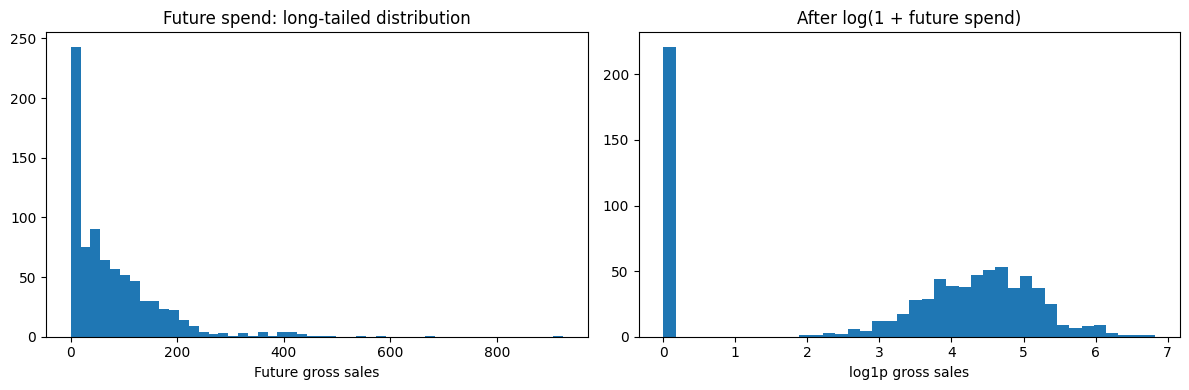

Training median 53.385 95th percentile 234.16899999999993


In [6]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(train.actual_future_spend,bins=50);axs[0].set_title('Future spend: long-tailed distribution');axs[0].set_xlabel('Future gross sales')
axs[1].hist(np.log1p(train.actual_future_spend),bins=40);axs[1].set_title('After log(1 + future spend)');axs[1].set_xlabel('log1p gross sales')
plt.tight_layout();plt.savefig(DIRS['figures']/'REQUIRED_long_tail_and_log_transform.png',dpi=160);plt.show()
print('Training median',train.actual_future_spend.median(),'95th percentile',train.actual_future_spend.quantile(.95))

### LAB 06 — Fit the established purchasing model without future leakage 🔎
Refit BG/NBD on the *historical snapshot at the TEST_CUTOFF*, not on any future test transaction. Estimate expected purchases in the next `HOLDOUT_DAYS`. Save the model and parameters. This is the comparable version of the Assignment 5.1 purchase model.

In [8]:

# ============================================================
# MAI 510 - MODULE 5 - ASSIGNMENT 5.2
# LAB 06 - BG/NBD MODEL (VALIDATION + SAVE FIX)
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import cloudpickle
from pathlib import Path
from IPython.display import display
from lifetimes import BetaGeoFitter

print("=" * 65)
print("RETAILVISION AI - LAB 06")
print("BG/NBD HISTORICAL MODEL")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1 - PREPARE DIRECTORIES
# ------------------------------------------------------------

models_dir = Path(DIRS["models"])
tables_dir = Path(DIRS["tables"])
proof_dir = Path(DIRS["proof"])

for folder in [models_dir, tables_dir, proof_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 2 - BUILD HISTORICAL CUSTOMER FEATURES
# ------------------------------------------------------------

required = ["frequency", "recency", "T"]

rf = test.set_index("CustomerID")[FEATURES].copy()

if not rf.index.is_unique:
    raise ValueError(
        "CustomerID values are duplicated in the historical "
        "snapshot. Review customer aggregation."
    )

missing = [c for c in required if c not in rf.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Use consistent numeric types
for column in required:
    rf[column] = pd.to_numeric(
        rf[column],
        errors="coerce"
    ).astype(float)

# ------------------------------------------------------------
# STEP 3 - DIAGNOSE THE ORIGINAL VALUES
# ------------------------------------------------------------

audit = rf[required].copy()

audit["difference"] = audit["recency"] - audit["T"]

# Use a small tolerance only for floating-point artifacts.
TOLERANCE = 1e-7

audit["invalid_nonfinite"] = ~np.isfinite(
    audit[required].to_numpy(dtype=float)
).all(axis=1)

audit["negative_frequency"] = audit["frequency"] < 0

audit["negative_recency"] = audit["recency"] < 0

audit["negative_T"] = audit["T"] < 0

audit["recency_exceeds_T"] = (
    audit["difference"] > TOLERANCE
)

audit["tiny_rounding_difference"] = (
    (audit["difference"] > 0)
    & (audit["difference"] <= TOLERANCE)
)

audit["invalid_zero_frequency_recency"] = (
    (audit["frequency"] == 0)
    & (audit["recency"].abs() > TOLERANCE)
)

audit["invalid_positive_frequency_recency"] = (
    (audit["frequency"] > 0)
    & (audit["recency"] <= 0)
)

audit["noninteger_frequency"] = (
    np.isfinite(audit["frequency"])
    & (
        np.abs(
            audit["frequency"] -
            np.round(audit["frequency"])
        ) > TOLERANCE
    )
)

print("\nDATA VALIDATION SUMMARY")

checks = [
    "invalid_nonfinite",
    "negative_frequency",
    "negative_recency",
    "negative_T",
    "recency_exceeds_T",
    "tiny_rounding_difference",
    "invalid_zero_frequency_recency",
    "invalid_positive_frequency_recency",
    "noninteger_frequency"
]

diagnostics = pd.DataFrame({
    "Check": checks,
    "Customer count": [
        int(audit[c].sum()) for c in checks
    ]
})

display(diagnostics)

# Save original values for reproducibility
audit.to_csv(
    tables_dir / "REQUIRED_BGNBD_input_audit.csv",
    index_label="CustomerID"
)

# ------------------------------------------------------------
# STEP 4 - IDENTIFY MATERIAL DATA ERRORS
# ------------------------------------------------------------

serious_checks = [
    "invalid_nonfinite",
    "negative_frequency",
    "negative_recency",
    "negative_T",
    "recency_exceeds_T",
    "invalid_positive_frequency_recency",
    "noninteger_frequency"
]

# A tiny positive recency with zero frequency may also be
# an insignificant floating-point artifact. Larger values
# are considered material errors.

serious_mask = audit[serious_checks].any(axis=1) | (
    (audit["frequency"] == 0)
    & (audit["recency"].abs() > TOLERANCE)
)

if serious_mask.any():

    bad = audit.loc[serious_mask].copy()

    bad.to_csv(
        tables_dir / "BGNBD_records_needing_review.csv",
        index_label="CustomerID"
    )

    print("\nDATA ISSUE FOUND")
    print("Customers needing review:", len(bad))

    display(
        bad.sort_values(
            "difference",
            ascending=False
        ).head(20)
    )

    raise ValueError(
        "Historical BG/NBD features contain materially "
        "invalid values. Review the saved audit and "
        "rebuild the customer features at TEST_CUTOFF. "
        "No customer records have been silently deleted."
    )

# ------------------------------------------------------------
# STEP 5 - CORRECT ONLY TINY ROUNDING DIFFERENCES
# ------------------------------------------------------------

rounding_mask = audit["tiny_rounding_difference"]

print(
    "\nTiny rounding differences corrected:",
    int(rounding_mask.sum())
)

# A recency value above T by <= 1e-7 days is treated
# as floating-point noise, not as a genuine purchase
# occurring after the cutoff.

rf.loc[rounding_mask, "recency"] = (
    rf.loc[rounding_mask, "T"]
)

zero_freq_mask = (
    (rf["frequency"] == 0)
    & (rf["recency"].abs() <= TOLERANCE)
)

rf.loc[zero_freq_mask, "recency"] = 0.0

rf["frequency"] = (
    rf["frequency"].round().astype(int)
)

# ------------------------------------------------------------
# STEP 6 - VALIDATE THE EXACT ARRAYS
# ------------------------------------------------------------

freq_array = rf["frequency"].to_numpy(
    dtype=np.int64,
    copy=True
)

rec_array = rf["recency"].to_numpy(
    dtype=np.float64,
    copy=True
)

age_array = rf["T"].to_numpy(
    dtype=np.float64,
    copy=True
)

assert np.isfinite(rec_array).all()
assert np.isfinite(age_array).all()
assert (freq_array >= 0).all()
assert (rec_array >= 0).all()
assert (age_array >= 0).all()
assert np.all(rec_array <= age_array)
assert np.all(rec_array[freq_array == 0] == 0)

# Save exactly what is supplied to lifetimes.
rf.to_csv(
    tables_dir / "REQUIRED_BGNBD_validated_features.csv",
    index_label="CustomerID"
)

print("\nVALIDATION PASSED")
print("Customers:", len(rf))
print("Maximum recency - T:", float(
    np.max(rec_array - age_array)
))

# ------------------------------------------------------------
# STEP 7 - FIT BG/NBD
# ------------------------------------------------------------

penalizer = 0.05 if DEMO_MODE else 0.01

bgf = BetaGeoFitter(
    penalizer_coef=penalizer
)

start = time.perf_counter()

# Pass aligned, validated NumPy arrays.
bgf.fit(
    freq_array,
    rec_array,
    age_array
)

baseline_fit_s = time.perf_counter() - start

print("\nBG/NBD MODEL FIT COMPLETE")
print("Training time:", round(baseline_fit_s, 2), "sec")

display(
    bgf.params_.to_frame("Estimate")
)

# ------------------------------------------------------------
# STEP 8 - PREDICT FUTURE PURCHASES
# ------------------------------------------------------------

rf["predicted_purchases"] = np.asarray(
    bgf.conditional_expected_number_of_purchases_up_to_time(
        HOLDOUT_DAYS,
        freq_array,
        rec_array,
        age_array
    ),
    dtype=float
)

rf["prob_alive"] = np.asarray(
    bgf.conditional_probability_alive(
        freq_array,
        rec_array,
        age_array
    ),
    dtype=float
)

if not np.isfinite(
    rf["predicted_purchases"].to_numpy()
).all():
    raise ValueError(
        "Non-finite BG/NBD predictions detected."
    )

if not np.isfinite(
    rf["prob_alive"].to_numpy()
).all():
    raise ValueError(
        "Non-finite probability estimates detected."
    )

# ------------------------------------------------------------
# STEP 9 - SAVE MODEL AND EVIDENCE
# ------------------------------------------------------------

# cloudpickle supports the lambda functions inside lifetimes.
model_path = models_dir / "BGNBD_heldout_cutoff.pkl"

with open(model_path, "wb") as file:
    cloudpickle.dump(bgf, file)

bgf.params_.to_csv(
    tables_dir / "REQUIRED_BG_NBD_parameters.csv"
)

rf.to_csv(
    tables_dir / "REQUIRED_BGNBD_holdout_predictions.csv",
    index_label="CustomerID"
)

metadata = {
    "assignment": "MAI 510 - Module 5 - Assignment 5.2",
    "model": "BG/NBD",
    "students": globals().get("STUDENT_NAME", ""),
    "customer_count": int(len(rf)),
    "holdout_days": float(HOLDOUT_DAYS),
    "penalizer": float(penalizer),
    "training_seconds": float(baseline_fit_s),
    "rounding_corrections": int(rounding_mask.sum()),
    "parameters": {
        k: float(v)
        for k, v in bgf.params_.items()
    }
}

(
    proof_dir / "REQUIRED_BGNBD_fit_metadata.json"
).write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# STEP 10 - DISPLAY RESULTS
# ------------------------------------------------------------

print("\nSAMPLE CUSTOMER PREDICTIONS")

display(
    rf[
        [
            "frequency",
            "recency",
            "T",
            "predicted_purchases",
            "prob_alive"
        ]
    ].head(10)
)

print("\nFILES SAVED")
print(model_path)
print(tables_dir / "REQUIRED_BG_NBD_parameters.csv")
print(tables_dir / "REQUIRED_BGNBD_holdout_predictions.csv")

print("\n" + "=" * 65)
print("LAB 06 COMPLETED SUCCESSFULLY")
print("=" * 65)


RETAILVISION AI - LAB 06
BG/NBD HISTORICAL MODEL

DATA VALIDATION SUMMARY


,Check,Customer count
0,invalid_nonfinite,0
1,negative_frequency,0
2,negative_recency,0
3,negative_T,0
4,recency_exceeds_T,0
5,tiny_rounding_difference,0
6,invalid_zero_frequency_recency,0
7,invalid_positive_frequency_recency,0
8,noninteger_frequency,0



Tiny rounding differences corrected: 0

VALIDATION PASSED
Customers: 450
Maximum recency - T: 0.0

BG/NBD MODEL FIT COMPLETE
Training time: 0.09 sec


,Estimate
r,1.511625e+00
alpha,8.177456e+01
a,1.067450e-14
b,4.669275e-06



SAMPLE CUSTOMER PREDICTIONS


,frequency,recency,T,predicted_purchases,prob_alive
CustomerID,,,,,
DEMO-00146,1,220.0,221.0,0.622152,1.0
DEMO-00421,3,23.0,173.0,1.328123,1.0
DEMO-00324,6,142.0,182.0,2.135808,1.0
DEMO-00195,9,219.0,225.0,2.569874,1.0
DEMO-00512,6,139.0,186.0,2.103904,1.0
DEMO-00130,2,108.0,161.0,1.084841,1.0
DEMO-00240,6,214.0,266.0,1.619934,1.0
DEMO-00115,0,0.0,254.0,0.337643,1.0
DEMO-00175,6,191.0,257.0,1.662970,1.0



FILES SAVED
/content/MAI510_M5_A52_Ivan_Suarez_20261124_224524/models/BGNBD_heldout_cutoff.pkl
/content/MAI510_M5_A52_Ivan_Suarez_20261124_224524/tables/REQUIRED_BG_NBD_parameters.csv
/content/MAI510_M5_A52_Ivan_Suarez_20261124_224524/tables/REQUIRED_BGNBD_holdout_predictions.csv

LAB 06 COMPLETED SUCCESSFULLY


### LAB 07 — Check and fit Gamma-Gamma; handle one-time buyers responsibly 🧪
The Gamma-Gamma assumption asks whether transaction frequency and monetary value are approximately unrelated among eligible repeat buyers. A correlation near zero does **not prove independence**. We report Pearson r and save the scatterplot; if assumptions appear weak, explicitly discuss the risk. Customers with no repeat purchases receive a **clearly labeled cohort-mean fallback** derived from eligible repeat buyers, not a fabricated individualized Gamma-Gamma estimate.

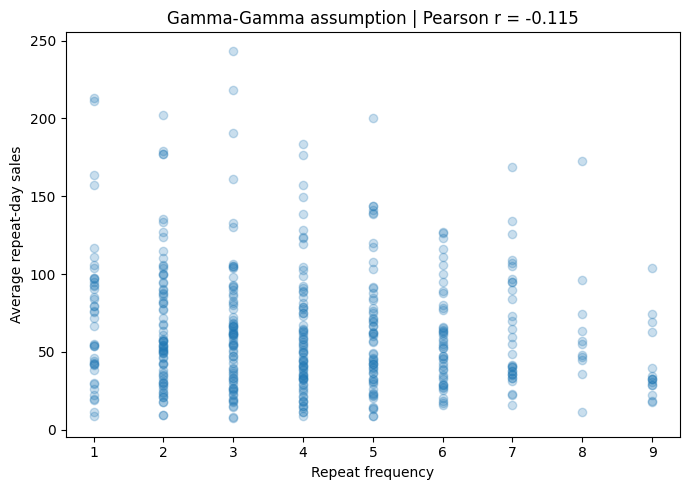

Gamma-Gamma Pearson r: -0.11470813948632219 | Additional time included in total 0.13 sec
Business caution: positive-sales revenue, not profit; no 12-month observed validation.


100

In [9]:
from scipy.stats import pearsonr
eligible=rf[(rf.frequency>0)&(rf.monetary_value>0)].copy()
assert len(eligible)>=20,'Not enough repeat customers for Gamma-Gamma fitting.'
if eligible.frequency.nunique()>1 and eligible.monetary_value.nunique()>1:
    corr_freq_money=float(pearsonr(eligible.frequency,eligible.monetary_value).statistic)
else:corr_freq_money=float('nan')
plt.figure(figsize=(7,5));plt.scatter(eligible.frequency,eligible.monetary_value,alpha=.24)
plt.title(f'Gamma-Gamma assumption | Pearson r = {corr_freq_money:.3f}')
plt.xlabel('Repeat frequency');plt.ylabel('Average repeat-day sales');plt.tight_layout()
plt.savefig(DIRS['figures']/'REQUIRED_gamma_gamma_assumption.png',dpi=160);plt.show()
t0=time.perf_counter()
ggf=GammaGammaFitter(penalizer_coef=0.05 if DEMO_MODE else 0.01)
ggf.fit(eligible.frequency,eligible.monetary_value)
baseline_fit_s+=time.perf_counter()-t0
with open(DIRS['models']/'GammaGamma_heldout_cutoff.pkl','wb') as f:pickle.dump(ggf,f)
ggf.params_.to_csv(DIRS['tables']/'REQUIRED_GammaGamma_parameters.csv')
repeat_values=np.asarray(ggf.conditional_expected_average_profit(
    eligible.frequency,eligible.monetary_value),dtype=float)
# Defined cohort-average fallback for one-time buyers; not a customer-specific Gamma-Gamma estimate.
rf['expected_sale_value']=float(np.mean(repeat_values))
rf.loc[eligible.index,'expected_sale_value']=repeat_values
rf['monetary_value_method']='repeat_buyer_GammaGamma'
rf.loc[~rf.index.isin(eligible.index),'monetary_value_method']='one_time_cohort_mean_proxy'
rf['probabilistic_predicted_future_spend']=(rf.predicted_purchases*rf.expected_sale_value).clip(lower=0)
prob_pred=rf['probabilistic_predicted_future_spend'].reindex(test.CustomerID).to_numpy()
print('Gamma-Gamma Pearson r:',corr_freq_money,'| Additional time included in total',round(baseline_fit_s,2),'sec')
print('Business caution: positive-sales revenue, not profit; no 12-month observed validation.')
(DIRS['proof']/'gamma_gamma_assumption.json').write_text(json.dumps({'pearson_r':corr_freq_money,'eligible_customers':len(eligible),'assumption_supported':None},indent=2))

### LAB 08 — Prepare neural inputs with train-only scaling 🧰
Only the training snapshots are allowed to teach `StandardScaler` the feature means and standard deviations. Applying scaling based on validation/test inputs would be data leakage. Every neural training row comes from the past and its label ends before our final held-out test begins.

In [10]:
import joblib
x_train=train[FEATURES].astype(float).replace([np.inf,-np.inf],np.nan).fillna(0)
x_valid=valid[FEATURES].astype(float).replace([np.inf,-np.inf],np.nan).fillna(0)
x_test=test[FEATURES].astype(float).replace([np.inf,-np.inf],np.nan).fillna(0)
scaler=StandardScaler()
Xtr=scaler.fit_transform(x_train);Xva=scaler.transform(x_valid);Xte=scaler.transform(x_test)
ytr=np.log1p(train.actual_future_spend.to_numpy(float))
yva=np.log1p(valid.actual_future_spend.to_numpy(float))
yte=test.actual_future_spend.to_numpy(float)
joblib.dump(scaler,DIRS['models']/'neural_feature_scaler.joblib')
(DIRS['proof']/'neural_feature_columns.json').write_text(json.dumps(FEATURES))
print('Neural features:',FEATURES,'| Training samples:',len(Xtr))

Neural features: ['frequency', 'recency', 'T', 'monetary_value'] | Training samples: 792


### LAB 09 — Create and train the neural regressor 🧠
Dense neural network: 32-unit hidden layer → dropout → 16-unit hidden layer → 1 regression output. Nonnegative target enforced by clipping predictions in **original currency**, not by changing labels. Early stopping monitors the earlier validation window. The reported parameter count describes model complexity; it is **not** training-set size.

In [11]:
model=keras.Sequential([
    layers.Input(shape=(len(FEATURES),)),
    layers.Dense(32,activation='relu'),
    layers.Dropout(.18),
    layers.Dense(16,activation='relu'),
    layers.Dense(1)
],name='RetailVision_NeuralRegressor')
model.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),loss=keras.losses.Huber(delta=1.0),metrics=['mae'])
model.summary()
start=time.perf_counter()
history=model.fit(Xtr,ytr,validation_data=(Xva,yva),epochs=NN_EPOCHS,batch_size=NN_BATCH,
    verbose=0,callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True)])
neural_train_s=time.perf_counter()-start
model.save(DIRS['models']/'neural_regressor.keras')
npred=np.asarray(model.predict(Xte,verbose=0),dtype=float).reshape(-1)
neural_pred=np.maximum(0,np.expm1(np.clip(npred,-15,20)))
print('Trained epochs:',len(history.history['loss']),'| Time:',round(neural_train_s,2),'sec | Parameters:',model.count_params())

Model: "RetailVision_NeuralRegressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705 (2.75 KB)

 Trainable params: 705 (2.75 KB)

 Non-trainable params: 0 (0.00 B)

Trained epochs: 12 | Time: 2.69 sec | Parameters: 705


### LAB 10 — Visualize training and validation curves 📉
If validation loss rises while training loss falls, that can indicate overfitting. The y-axis here is **Huber loss in log-transformed target space**, not MAE in currency.

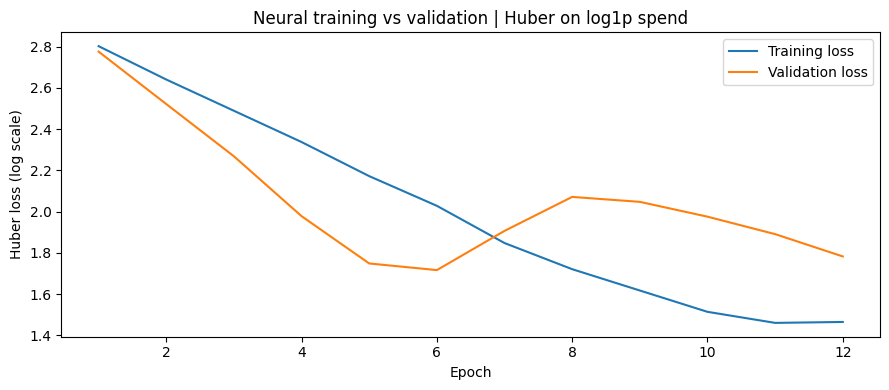

In [12]:
hist=pd.DataFrame(history.history)
hist.index=np.arange(1,len(hist)+1);hist.index.name='Epoch'
hist.to_csv(DIRS['tables']/'REQUIRED_neural_training_history.csv')
plt.figure(figsize=(9,4));plt.plot(hist.index,hist['loss'],label='Training loss');plt.plot(hist.index,hist['val_loss'],label='Validation loss')
plt.title('Neural training vs validation | Huber on log1p spend');plt.xlabel('Epoch');plt.ylabel('Huber loss (log scale)')
plt.legend();plt.tight_layout();plt.savefig(DIRS['figures']/'REQUIRED_training_validation_curves.png',dpi=160);plt.show()

### LAB 11 — Fair held-out scorecard: MAE + Pearson correlation 🎯
Both methods predict **gross positive-sale revenue over exactly the same future days for exactly the same customers**. MAE is measured in the original currency. Pearson r measures linear association; it is not a financial benefit or causal effect. We also record zero-spend prevalence and runtimes for discussion. This can reveal whether a model predicts the right customers but systematically misses their spending amounts.

In [13]:
actual=test.actual_future_spend.to_numpy(float)
assert len(prob_pred)==len(neural_pred)==len(actual)==len(test)
def safe_pearson(x,y):
    if np.std(x)<1e-12 or np.std(y)<1e-12:return float('nan')
    return float(pearsonr(x,y).statistic)
def score(label,pred,train_seconds,complexity):
    return {'Model':label,'MAE_currency':mean_absolute_error(actual,pred),
            'Pearson_r':safe_pearson(pred,actual),'Train_seconds':train_seconds,
            'Model_complexity':complexity,'Customers_evaluated':len(actual),
            'Forecast_days':HOLDOUT_DAYS}
comparison=pd.DataFrame([
    score('BG/NBD + Gamma-Gamma',prob_pred,baseline_fit_s,f'{len(bgf.params_)+len(ggf.params_)} fitted parameters'),
    score('Keras neural regression',neural_pred,neural_train_s,f'{model.count_params()} neural parameters')])
comparison.to_csv(DIRS['tables']/'REQUIRED_model_comparison_MAE_correlation.csv',index=False)
results=test[['CustomerID']+FEATURES+['actual_future_spend']].copy()
results['probabilistic_predicted_future_spend']=prob_pred
results['neural_predicted_future_spend']=neural_pred
results['probabilistic_abs_error']=abs(results.probabilistic_predicted_future_spend-results.actual_future_spend)
results['neural_abs_error']=abs(results.neural_predicted_future_spend-results.actual_future_spend)
results.to_csv(DIRS['tables']/'REQUIRED_all_customer_model_predictions.csv',index=False)
display(comparison.style.format({'MAE_currency':'{:,.2f}','Pearson_r':'{:.3f}','Train_seconds':'{:.2f}'}))

,Model,MAE_currency,Pearson_r,Train_seconds,Model_complexity,Customers_evaluated,Forecast_days
0,BG/NBD + Gamma-Gamma,65.63,0.448,0.13,7 fitted parameters,450,75
1,Keras neural regression,"1,847.62",0.001,2.69,705 neural parameters,450,75


### LAB 12 — Predicted versus actual: where do models miss? 📍
A perfect forecast falls on the diagonal. Large positive predictions for customers who spend zero cause costly errors; very high spenders often appear as outliers. The figure retains the raw currency scale, plus log1p visualization to expose patterns obscured by the tail.

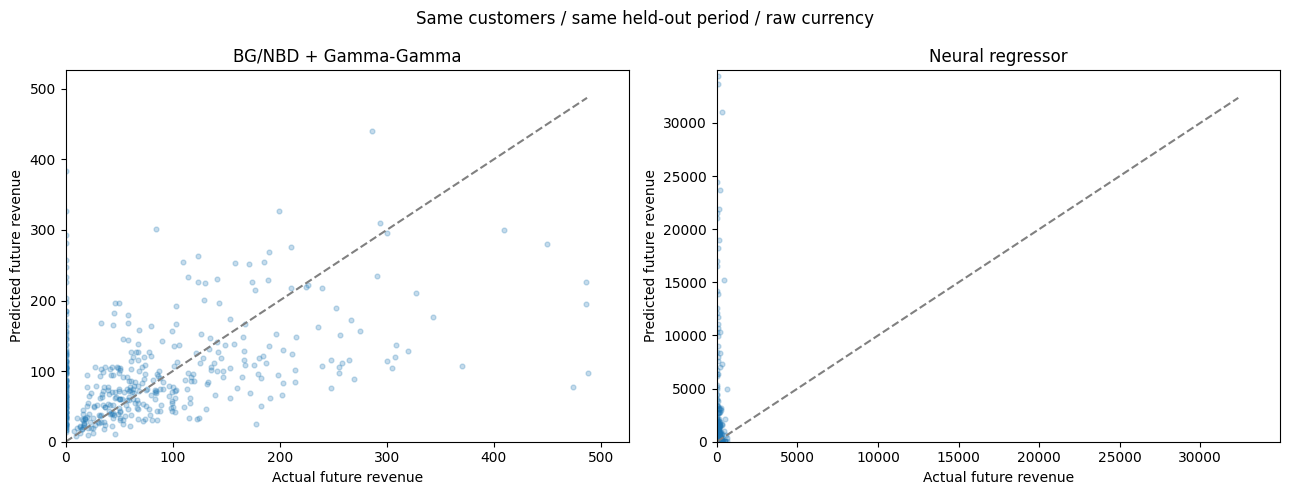

In [14]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,pred,title in [(axes[0],prob_pred,'BG/NBD + Gamma-Gamma'),(axes[1],neural_pred,'Neural regressor')]:
    ax.scatter(actual,pred,alpha=.25,s=12)
    cap=max(np.percentile(actual,99),np.percentile(pred,99),1)
    ax.plot([0,cap],[0,cap],linestyle='--',color='gray')
    ax.set_xlim(0,cap*1.08);ax.set_ylim(0,cap*1.08)
    ax.set_title(title);ax.set_xlabel('Actual future revenue');ax.set_ylabel('Predicted future revenue')
plt.suptitle('Same customers / same held-out period / raw currency')
plt.tight_layout();plt.savefig(DIRS['figures']/'REQUIRED_predicted_vs_actual.png',dpi=160);plt.show()
fig=go.Figure()
fig.add_trace(go.Scatter(x=actual,y=prob_pred,mode='markers',name='Probabilistic',opacity=.5))
fig.add_trace(go.Scatter(x=actual,y=neural_pred,mode='markers',name='Neural',opacity=.5))
fig.update_xaxes(type='log',title='Actual + 1 (log axis)');fig.update_yaxes(type='log',title='Predicted + 1 (log axis)')
# Plotly log axes cannot display zero; use plus-one values instead
for trace,pred in zip(fig.data,[prob_pred,neural_pred]):
    trace.x=actual+1;trace.y=pred+1
fig.update_layout(title='Log-scale comparison: actual + 1 vs predicted + 1')
fig.write_html(str(DIRS['dashboards']/'REQUIRED_interactive_predictions.html'));fig.show()

### LAB 13 — The top-50 customer challenge 🏆
For each model, rank customers by predicted **future** sales, not by the actual future result. Determine intersection count, union, and percentage of the 50-name lists shared. Save both lists with their customer IDs. In the demo subset, there are still at least 50 historical test customers. **A model can have a low MAE yet disagree on whom to prioritize.**

In [15]:
K=50
assert len(results)>=K
top_p=results.sort_values(['probabilistic_predicted_future_spend','CustomerID'],ascending=[False,True]).head(K).copy()
top_n=results.sort_values(['neural_predicted_future_spend','CustomerID'],ascending=[False,True]).head(K).copy()
set_p=set(top_p.CustomerID);set_n=set(top_n.CustomerID)
both=set_p&set_n;only_p=set_p-set_n;only_n=set_n-set_p
ranking_stats={'top_k':K,'in_both':len(both),'only_probabilistic':len(only_p),'only_neural':len(only_n),
               'overlap_pct_of_top_k':100*len(both)/K,'jaccard_pct':100*len(both)/len(set_p|set_n)}
for label,frame in [('probabilistic',top_p),('neural',top_n)]:
    frame.to_csv(DIRS['tables']/f'REQUIRED_TOP50_{label}_customers.csv',index=False)
pd.DataFrame({'CustomerID':sorted(both)}).to_csv(DIRS['tables']/'REQUIRED_TOP50_shared_customers.csv',index=False)
(DIRS['proof']/'REQUIRED_top50_overlap.json').write_text(json.dumps(ranking_stats,indent=2))
print(json.dumps(ranking_stats,indent=2))
fig=go.Figure(go.Bar(x=['Both','Probabilistic only','Neural only'],y=[len(both),len(only_p),len(only_n)],
                     text=[len(both),len(only_p),len(only_n)],textposition='outside'))
fig.update_layout(title=f'Top-50 customer overlap: {len(both)}/50 shared',yaxis_title='Customer count')
fig.write_html(str(DIRS['dashboards']/'REQUIRED_top50_overlap.html'));fig.show()

{
  "top_k": 50,
  "in_both": 11,
  "only_probabilistic": 39,
  "only_neural": 39,
  "overlap_pct_of_top_k": 22.0,
  "jaccard_pct": 12.359550561797754
}


### LAB 14 — Business decision dashboard: the jury votes 📊
This four-panel Plotly dashboard displays held-out MAE, Pearson correlation, model prediction totals, and ranking overlap. Hover over marks, show it to the class, and ask students to vote **before** reading the measured winner. All charts are generated from your experiment, not invented scores.

In [16]:
d=make_subplots(rows=2,cols=2,subplot_titles=['MAE (lower is better)','Pearson r (higher association)',
    'Total forecast vs observed sales','Top-50 overlap'],specs=[[{},{}],[{},{}]])
d.add_trace(go.Bar(x=comparison.Model,y=comparison.MAE_currency,name='MAE',showlegend=False),row=1,col=1)
d.add_trace(go.Bar(x=comparison.Model,y=comparison.Pearson_r,name='Correlation',showlegend=False),row=1,col=2)
d.add_trace(go.Bar(x=['Actual','Probabilistic','Neural'],y=[actual.sum(),prob_pred.sum(),neural_pred.sum()],showlegend=False),row=2,col=1)
d.add_trace(go.Bar(x=['Shared','Prob. only','Neural only'],y=[len(both),len(only_p),len(only_n)],showlegend=False),row=2,col=2)
d.update_layout(title=f'RetailVision AI | {STUDENT_NAME} | {HOLDOUT_DAYS}-day held-out business results',height=780,template='plotly_white')
d.write_html(str(DIRS['dashboards']/'REQUIRED_EXECUTIVE_MODEL_SHOWDOWN_DASHBOARD.html'),include_plotlyjs=True)
d.show()
mae_winner=comparison.sort_values('MAE_currency').iloc[0]['Model']
print('Lowest MAE:',mae_winner)

Lowest MAE: BG/NBD + Gamma-Gamma


### LAB 15 — Export a visual summary dashboard PNG + CSV proof 📝
For easy LMS grading, this static figure captures the same metrics without needing a live HTML viewer. Also export the top 20 biggest errors for both models. Watch for outliers; they may dominate business cost.

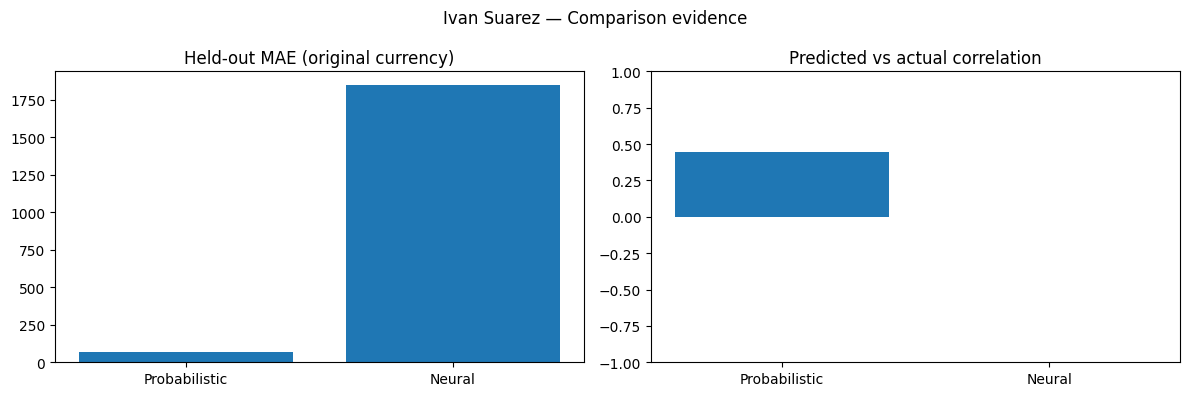

In [17]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].bar(['Probabilistic','Neural'],comparison.MAE_currency);axs[0].set_title('Held-out MAE (original currency)')
axs[1].bar(['Probabilistic','Neural'],comparison.Pearson_r);axs[1].set_title('Predicted vs actual correlation');axs[1].set_ylim(-1,1)
plt.suptitle(f'{STUDENT_NAME} — Comparison evidence');plt.tight_layout()
plt.savefig(DIRS['figures']/'REQUIRED_comparison_summary.png',dpi=160);plt.show()
results.nlargest(20,'probabilistic_abs_error').to_csv(DIRS['tables']/'largest_probabilistic_errors.csv',index=False)
results.nlargest(20,'neural_abs_error').to_csv(DIRS['tables']/'largest_neural_errors.csv',index=False)

### LAB 16 — Student analysis and evidence requirements ✍️
**Required paragraph:** Why does the smaller model win or lose? Reference its assumptions about repeat purchasing and monetary independence, and the neural model's learned functional relationships, along with measured MAE, correlation, ranking overlap and complexity. The AI reviewer (optional) can make your writing clearer **but cannot generate or replace your judgment**. Enter your own paragraph here; it will go into the Word report.

In [18]:
STUDENT_CONCLUSION = '''[REQUIRED STUDENT WRITING] Which model would you deploy? Refer to BOTH MAE and correlation on the held-out future window, the top-50 overlap, training cost/model size and differing assumptions. Explain why the smaller model did or did not win.'''
STUDENT_AI_VERIFICATION = '''[OPTIONAL] If you used Ollama/Qwen, write what it suggested, what you checked against your CSV results, and what advice you accepted/rejected.'''
print('Your conclusion is',len(STUDENT_CONCLUSION.split()),'words. Replace the bracketed prompt before final submission.')

Your conclusion is 38 words. Replace the bracketed prompt before final submission.


### LAB 17 — Prepare safe AI review evidence (always available) 🤖
We send **aggregated metrics and assumptions**, not names, customer IDs or raw transactions, to Qwen. The AI prompt asks for a skeptical review of the evidence and improvements to the student’s writing. Save this even if you skip Ollama, so you can use it with an instructor-approved alternative.

In [19]:
ai_evidence={'student_name':STUDENT_NAME,'demo_mode':DEMO_MODE,'source':SOURCE,
 'test_cutoff':str(TEST_CUTOFF.date()),'holdout_days':HOLDOUT_DAYS,'test_customers':len(test),
 'probabilistic':{'mae':float(comparison.iloc[0].MAE_currency),'pearson_r':float(comparison.iloc[0].Pearson_r),
                  'parameters':len(bgf.params_)+len(ggf.params_),'gamma_frequency_value_pearson_r':corr_freq_money},
 'neural':{'mae':float(comparison.iloc[1].MAE_currency),'pearson_r':float(comparison.iloc[1].Pearson_r),
           'parameters':int(model.count_params()),'trained_epochs':len(hist)},
 'top50_overlap_count':len(both),'top50_overlap_pct':ranking_stats['overlap_pct_of_top_k'],
 'student_draft':STUDENT_CONCLUSION,
 'limits':['Positive-sale revenue, not profit','Historical customer cohort only','75-day horizon; not 12-month validation',
           'Gamma-Gamma frequency-value independence is an assumption, not proven by correlation',
           'Training snapshots share some customers; future test is entirely chronological']}
AI_PROMPT=('You are a skeptical graduate-level customer lifetime value reviewer. '
 'Use ONLY the supplied JSON evidence. Return headings: (1) Evidence-based strengths, '
 '(2) Weak or unsupported claims, (3) Which model to recommend and uncertainty, '
 '(4) Three concrete improvements to the STUDENT DRAFT that preserve its authorship, '
 '(5) Checks needed before business deployment. No invented figures or customer details. '
 'Do NOT call a 75-day prediction a validated 12-month CLV. Gross sales is not profit. '
 'Do NOT claim zero correlation proves independence. Explicitly flag synthetic/demo results. '
 'Do not silently rewrite the whole report. EVIDENCE:\n'+json.dumps(ai_evidence,indent=2))
(DIRS['ai_review']/'OPTIONAL_AI_REVIEW_PROMPT.txt').write_text(AI_PROMPT)
(DIRS['ai_review']/'OPTIONAL_AI_REVIEW_EVIDENCE.json').write_text(json.dumps(ai_evidence,indent=2))
print('Saved AI review prompt and aggregate evidence (no individual customer records).')

Saved AI review prompt and aggregate evidence (no individual customer records).


### LAB 18 — Ollama/Qwen installer (optional; failure-safe) 🛠️
**Default `RUN_OLLAMA=False`**. Hosted Colab may restrict Ollama downloads, memory, networking, or subprocesses. Only enable this if the class has time. The notebook itself never depends on AI for the required grades. This lab downloads the official installer and executes it, launches a local server, and pulls `qwen3:0.6b`. You can skip to LAB 20 if setup fails.

In [20]:
RUN_OLLAMA=False             # True = try local Qwen3 in Colab
QWEN_MODEL='qwen3:0.6b'     # smallest model for classroom experimentation
ollama_ready=False
ollama_setup_status='Skipped by student preference'
if RUN_OLLAMA:
    import subprocess, urllib.request
    try:
        installer=Path('/content/ollama_install_m5_a52.sh')
        urllib.request.urlretrieve('https://ollama.com/install.sh',str(installer))
        install=subprocess.run(['sh',str(installer)],capture_output=True,text=True,timeout=180)
        (DIRS['ai_review']/'ollama_install_log.txt').write_text(install.stdout+'\n'+install.stderr)
        if install.returncode!=0:raise RuntimeError('Installer exit code '+str(install.returncode))
        serverlog=open(DIRS['ai_review']/'ollama_server.log','w')
        server=subprocess.Popen(['ollama','serve'],stdout=serverlog,stderr=subprocess.STDOUT)
        ok=False
        for attempt in range(25):
            try:
                with urllib.request.urlopen('http://127.0.0.1:11434/api/tags',timeout=3) as rsp:
                    ok=(rsp.status==200)
                if ok:break
            except Exception:pass
            time.sleep(1)
        if not ok:raise RuntimeError('Ollama local API did not respond')
        pulled=subprocess.run(['ollama','pull',QWEN_MODEL],capture_output=True,text=True,timeout=360)
        (DIRS['ai_review']/'ollama_pull_log.txt').write_text(pulled.stdout+'\n'+pulled.stderr)
        if pulled.returncode!=0:raise RuntimeError('Model pull failed')
        ollama_ready=True
        ollama_setup_status='Ready: '+QWEN_MODEL
    except Exception as e:
        ollama_setup_status=f'Optional setup unavailable: {type(e).__name__}: {e}'
print(ollama_setup_status)
(DIRS['ai_review']/'ollama_setup_status.txt').write_text(ollama_setup_status)

Skipped by student preference


29

### LAB 19 — Ask Qwen to review the measured findings 🧐
AI is a **reviewer**, not an evaluator that changes model scores. We request a compact response and save the full text for transparency. Students should compare every numerical statement in the AI response with the required CSV. If Ollama is unavailable, the reviewer prompt file remains available for a permitted alternative.

In [21]:
AI_REVIEW_TEXT='Optional Ollama review not run; use OPTIONAL_AI_REVIEW_PROMPT.txt with an approved AI tool.'
if RUN_OLLAMA and ollama_ready:
    try:
        import urllib.request
        payload=json.dumps({'model':QWEN_MODEL,'messages':[{'role':'user','content':AI_PROMPT}],
           'stream':False,'think':False,'options':{'temperature':0.2,'num_predict':650}}).encode()
        req=urllib.request.Request('http://127.0.0.1:11434/api/chat',data=payload,
            headers={'Content-Type':'application/json'},method='POST')
        with urllib.request.urlopen(req,timeout=240) as res:
            response=json.load(res)
        AI_REVIEW_TEXT=response.get('message',{}).get('content','No readable message returned')
    except Exception as exc:
        AI_REVIEW_TEXT=f'Ollama review error: {type(exc).__name__}: {exc}; use saved prompt instead.'
(DIRS['ai_review']/'OPTIONAL_QWEN_REVIEW.txt').write_text(AI_REVIEW_TEXT)
print(AI_REVIEW_TEXT[:6000])

Optional Ollama review not run; use OPTIONAL_AI_REVIEW_PROMPT.txt with an approved AI tool.


### LAB 20 — The human-in-the-loop challenge 🎮
Ask a partner or your instructor: Does Qwen claim the neural network is automatically better? Does it confuse correlation with causation? Does it misread synthetic results as real business evidence? Your score is based on **your own justified conclusion**, not how enthusiastically AI endorses it.

In [22]:
AI_REVIEW_CHECKLIST={
  'all_numbers_checked_against_csv':'STUDENT TO COMPLETE',
  'gross_sales_not_confused_with_profit':'STUDENT TO COMPLETE',
  '75_day_holdout_not_confused_with_12_month_forecast':'STUDENT TO COMPLETE',
  'gamma_gamma_independence_not_claimed_proven':'STUDENT TO COMPLETE',
  'student_wrote_own_final_judgment':'STUDENT TO COMPLETE'}
(DIRS['ai_review']/'OPTIONAL_AI_FACT_CHECK.json').write_text(json.dumps(AI_REVIEW_CHECKLIST,indent=2))
print('Review the checklist and independently update the file if using AI.')

Review the checklist and independently update the file if using AI.


### LAB 21 — Make the named Word report automatically 📄
The report contains your name, real measured comparison results, time split, ranking overlap, and key chart. It includes a **required paragraph placeholder** if you have not written your own judgment. Open the Word file and edit the text before final submission. The optional AI critique is placed in its own section, not presented as student-authored work.

In [23]:
from docx.shared import Inches,Pt,RGBColor
report=Document()
sec=report.sections[0];sec.header.paragraphs[0].text='MAI 510 | Module 5 | RetailVision AI'
report.add_heading('Assignment 5.2 — A Neural Regressor on the Same Question',0)
report.add_paragraph('Student: '+STUDENT_NAME)
report.add_paragraph('Dataset: '+SOURCE+'  |  Practice/demo: '+str(DEMO_MODE))
report.add_paragraph(f'Temporal holdout: {TEST_CUTOFF.date()} through {LAST_DAY.date()} | {HOLDOUT_DAYS} days')
report.add_heading('1. Model comparison on the future holdout',level=1)
t=report.add_table(rows=1,cols=5);t.style='Light Shading Accent 1'
for cell,val in zip(t.rows[0].cells,['Model','MAE','Pearson r','Train seconds','Complexity']):cell.text=val
for _,r in comparison.iterrows():
    cells=t.add_row().cells
    for cell,val in zip(cells,[str(r.Model),f'{r.MAE_currency:.2f}',f'{r.Pearson_r:.3f}',
                   f'{r.Train_seconds:.1f}',str(r.Model_complexity)]):cell.text=val
report.add_paragraph('All rows are measured against the same customers and future gross positive-sale revenue target. Currency depends on the supplied dataset.')
report.add_heading('2. Top-50 ranking overlap',level=1)
report.add_paragraph(f'Overlap: {len(both)} of 50 customers ({ranking_stats["overlap_pct_of_top_k"]:.1f}%). '
 f'Probabilistic-only: {len(only_p)}. Neural-only: {len(only_n)}.')
report.add_heading('3. Evidence figure',level=1)
report.add_picture(str(DIRS['figures']/'REQUIRED_comparison_summary.png'),width=Inches(5.8))
report.add_heading('4. Required student judgment — your own words',level=1)
report.add_paragraph(STUDENT_CONCLUSION)
report.add_heading('5. Assumptions and limitations',level=1)
report.add_paragraph(f'Gamma-Gamma frequency/value Pearson correlation: {corr_freq_money:.3f}. '
  'No correlation result alone proves independence. BG/NBD models repeat transactions; Gamma-Gamma models monetary value; neural regression learns nonlinear associations from engineered features. '
  'Only positive sales are modeled (not profitability), and 75-day future performance cannot verify a 12-month CLV forecast.')
report.add_heading('6. Optional AI reviewer',level=1)
report.add_paragraph('AI participation: '+ollama_setup_status)
report.add_paragraph(STUDENT_AI_VERIFICATION)
report.add_paragraph('Qwen output (clearly labeled machine-generated; verify before using):')
report.add_paragraph(AI_REVIEW_TEXT[:4200])
report_path=DIRS['reports']/f'{SAFE_NAME}_MAI510_Module5_Assignment_5_2_Report_DRAFT.docx'
report.save(report_path)
print('Report:',report_path)

Report: /content/MAI510_M5_A52_Ivan_Suarez_20261124_224524/reports/Ivan_Suarez_MAI510_Module5_Assignment_5_2_Report_DRAFT.docx


### LAB 22 — Final evidence audit and student upload 📁
The notebook verifies that all required CSVs/charts and the Word draft exist. Because Colab cannot reliably copy its **own current `.ipynb` file automatically**, download it through **File → Download → Download .ipynb**, and upload that exported notebook into this cell. Upload your completed Word report as well if you edited the generated draft. You can also attach your Assignment 5.1 notebook or ZIP here to satisfy the requirement to include both notebooks.

In [24]:
from google.colab import files
required=[
 DIRS['tables']/'REQUIRED_chronological_splits.csv',
 DIRS['tables']/'REQUIRED_training_customer_snapshots.csv',
 DIRS['tables']/'REQUIRED_validation_customer_snapshots.csv',
 DIRS['tables']/'REQUIRED_heldout_test_customer_snapshots.csv',
 DIRS['tables']/'REQUIRED_model_comparison_MAE_correlation.csv',
 DIRS['tables']/'REQUIRED_all_customer_model_predictions.csv',
 DIRS['tables']/'REQUIRED_TOP50_probabilistic_customers.csv',
 DIRS['tables']/'REQUIRED_TOP50_neural_customers.csv',
 DIRS['proof']/'REQUIRED_top50_overlap.json',
 DIRS['figures']/'REQUIRED_training_validation_curves.png',
 DIRS['figures']/'REQUIRED_predicted_vs_actual.png',
 DIRS['figures']/'REQUIRED_comparison_summary.png',
 DIRS['dashboards']/'REQUIRED_EXECUTIVE_MODEL_SHOWDOWN_DASHBOARD.html',
 DIRS['models']/'neural_regressor.keras',report_path]
status=pd.DataFrame([{'File':str(p.relative_to(BASE)),'Present':p.exists(),
 'Bytes':p.stat().st_size if p.exists() else 0} for p in required])
display(status)
assert status.Present.all(),'Required evidence missing. Rerun affected lab.'
status.to_csv(DIRS['proof']/'REQUIRED_artifact_audit.csv',index=False)
UPLOAD_NOTEBOOKS_AND_COMPLETED_REPORTS=False  # Set True and run to attach final files
if UPLOAD_NOTEBOOKS_AND_COMPLETED_REPORTS:
    up=files.upload()
    for name,content in up.items():
        (DIRS['submission_uploads']/Path(name).name).write_bytes(content)
else: print('IMPORTANT: Set UPLOAD_NOTEBOOKS_AND_COMPLETED_REPORTS=True to add executed .ipynb and final report before ZIP.')

,File,Present,Bytes
0,tables/REQUIRED_chronological_splits.csv,True,216
1,tables/REQUIRED_training_customer_snapshots.csv,True,38459
2,tables/REQUIRED_validation_customer_snapshots.csv,True,21399
3,tables/REQUIRED_heldout_test_customer_snapshot...,True,25255
4,tables/REQUIRED_model_comparison_MAE_correlati...,True,309
5,tables/REQUIRED_all_customer_model_predictions...,True,53483
6,tables/REQUIRED_TOP50_probabilistic_customers.csv,True,6305
7,tables/REQUIRED_TOP50_neural_customers.csv,True,6239
8,proof/REQUIRED_top50_overlap.json,True,152
9,figures/REQUIRED_training_validation_curves.png,True,71078


IMPORTANT: Set UPLOAD_NOTEBOOKS_AND_COMPLETED_REPORTS=True to add executed .ipynb and final report before ZIP.


### LAB 23 — FINAL STEP: create and download your named submission ZIP 🎒
Everything under your named run folder is packaged, including original source evidence, prepared snapshots, models, tables, PNGs, interactive HTML dashboards, report draft, optional AI evidence, and files uploaded in LAB 22. If your report still contains `[REQUIRED STUDENT WRITING]`, **it is not yet complete**. The notebook is not automatically included unless you upload it in LAB 22.

In [25]:
readme=f'''MAI 510 | Module 5 | Assignment 5.2
Student: {STUDENT_NAME}
Source: {SOURCE}
Demo mode: {DEMO_MODE}
Temporal holdout: {TEST_CUTOFF.date()} → {LAST_DAY.date()}
Metric target: 75-day gross positive-sale revenue (NOT profit; NOT 12-month validated CLV)
Required: add executed A51 and A52 notebooks in LAB 22; complete the student paragraph in the Word report.
AI assistance is optional. Independently verify all numerical claims. Synthetic/demo mode is practice only.
'''
(BASE/'README_SUBMISSION.txt').write_text(readme)
zip_path=Path('/content')/f'{SAFE_NAME}_MAI510_Module5_Assignment_5_2_Submission_{RUN_ID}.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in BASE.rglob('*'):
        if p.is_file():z.write(p,arcname=str(p.relative_to(BASE)))
with zipfile.ZipFile(zip_path) as z:assert z.testzip() is None
print('FINAL SUBMISSION:',zip_path,'| MB',round(zip_path.stat().st_size/1e6,2))
print('For assessment: use real data with DEMO_MODE=False and include completed reports and both executed notebooks.')
files.download(str(zip_path))

FINAL SUBMISSION: /content/Ivan_Suarez_MAI510_Module5_Assignment_5_2_Submission_20261124_224524.zip | MB 4.6
For assessment: use real data with DEMO_MODE=False and include completed reports and both executed notebooks.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>